In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [4]:
ticker = yf.Ticker('TSLA')

In [71]:
??yf.Ticker

Init signature: yf.Ticker(ticker, session=None)
Docstring:      <no docstring>
Source:        
class Ticker(TickerBase):
    def __init__(self, ticker, session=None):
        super(Ticker, self).__init__(ticker, session=session)
        self._expirations = {}
        self._underlying  = {}

    def __repr__(self):
        return f'yfinance.Ticker object <{self.ticker}>'

    def _download_options(self, date=None):
        if date is None:
            url = f"{_BASE_URL_}/v7/finance/options/{self.ticker}"
        else:
            url = f"{_BASE_URL_}/v7/finance/options/{self.ticker}?date={date}"

        r = self._data.get(url=url).json()
        if len(r.get('optionChain', {}).get('result', [])) > 0:
            for exp in r['optionChain']['result'][0]['expirationDates']:
                self._expirations[_pd.Timestamp(exp, unit='s').strftime('%Y-%m-%d')] = exp

            self._underlying = r['optionChain']['result'][0].get('quote', {})

            opt = r['optionChain']['result'][

In [72]:
ticker.info

{'address1': '1 Tesla Road',
 'city': 'Austin',
 'state': 'TX',
 'zip': '78725',
 'country': 'United States',
 'phone': '512 516 8177',
 'website': 'https://www.tesla.com',
 'industry': 'Auto Manufacturers',
 'industryKey': 'auto-manufacturers',
 'industryDisp': 'Auto Manufacturers',
 'sector': 'Consumer Cyclical',
 'sectorKey': 'consumer-cyclical',
 'sectorDisp': 'Consumer Cyclical',
 'longBusinessSummary': 'Tesla, Inc. designs, develops, manufactures, leases, and sells electric vehicles, and energy generation and storage systems in the United States, China, and internationally. The company operates in two segments, Automotive; and Energy Generation and Storage. The company offers electric vehicles, as well as sells automotive regulatory credits; and non-warranty maintenance services and collision, automotive insurance services, as well as part sales and retail merchandise sale. It also provides sedans and sport utility vehicles through direct and used vehicle sales, a network of Tesl

In [73]:
ticker.analyst_price_targets

{'current': 383.955,
 'high': 600.0,
 'low': 128.11,
 'mean': 396.56894,
 'median': 412.5}

In [5]:
# data acquisition and splitting 
data = ticker.history(period='5y')
train_data = data.loc[data.index < '2026-01-01']
test_data = data.drop(train_data.index)

Text(0.5, 1.0, 'Tesla (TSLA) stock price (USD)')

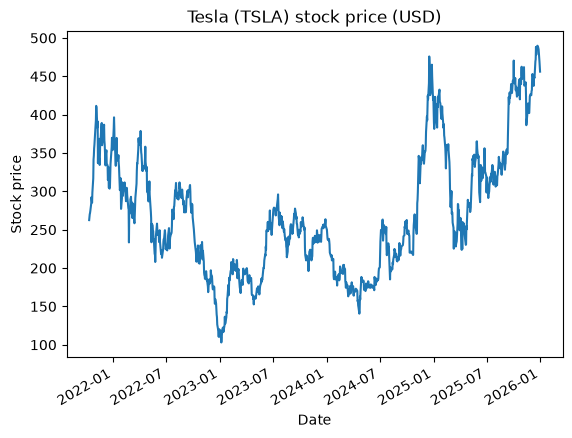

In [75]:
plt.plot(train_data['Open'])

 # gcf -get current figure
 # and autoformat the x-axis, since it's overlapping 
plt.gcf().autofmt_xdate() 
plt.xlabel("Date")
plt.ylabel("Stock price")
plt.title("Tesla (TSLA) stock price (USD)")

Text(0.5, 1.0, 'Tesla (TSLA) stock price (USD)')

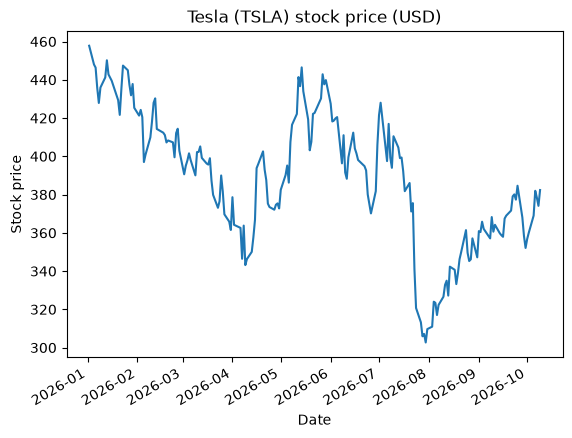

In [76]:
plt.plot(test_data['Open'])
plt.gcf().autofmt_xdate()
plt.xlabel("Date")
plt.ylabel("Stock price")
plt.title("Tesla (TSLA) stock price (USD)")

a) Build the fourth-order empirical increment model using only the first four years. Simulate 252 future
increments by independent sampling from the observed increments or from an explicitly specified histogram
model.

In [6]:
def compute_increments(data: list[float]) -> list[np.ndarray]:

    """ computes the first four order incremnets 
    args: data (as a list)

    returns: the list of increments 
    """

    # .iloc -> access by row position
    first_order = [np.log(data[k]) - np.log(data[k -1]) for k in range(1, len(data))]

    second_order = [np.log(data[k]) - 2 * np.log(data[k -1]) + np.log(data[k - 2]) for k in range(2, len(data))]

    third_order = [np.log(data[k])
            - 3 * np.log(data[k -1])
            + 3 * np.log(data[k - 2])
            - np.log(data[3])
            for k in range(3, len(data))]
    
    fourth_order = [np.log(data[k])  
            - 4 * np.log(data[k - 1])
            + 6 * np.log(data[k - 2])
            - 4 * np.log(data[k - 3])
            + np.log(data[k - 4])
            for k in range(4, len(data))]

    return [first_order, second_order, third_order, fourth_order]

In [9]:
def plot_histogram(
    data: np.ndarray, 
    x_label: str,
    y_label: str,
    title: str,
    color_idx: int, 
    bins: int=50,
    edgecolor: str='black',
    alphas: tuple[float]=[0.7, 0.4],
    density: bool=True,
    x_axv_line: float=0,
    linestyle: str='--') -> None:

    """plots a histogram of 4th order increments

    args: data -a 1D list of items
          x_label -the label for the x_axis
          y_label -the label for the y_axis
          title -the title of the plot
          color_idx -for choosing different colors
          bins -the how many items inside a bucket / bin
          edgecolor -marker edgecolor
          alphas -a 2-tuple for line opacity (one for the histogram, one for tge grid)
          density -specifies whether or not a density chart is wanted
          x_axv_line: the coordinate on x_axis where a vertical line shall be drawn,
          linestyle: the linestyle for the axv_line'
    """
    colors = ['purple', 'red', 'green', 'orange']

    plt.hist(
        data, 
        bins=bins, 
        color=colors[color_idx], 
        edgecolor=edgecolor, 
        alpha=alphas[0], 
        density=density)
    plt.title(label=title)
    plt.xlabel(xlabel=x_label)
    plt.ylabel(ylabel=y_label)

    # a different idx for a color
    new_color = colors[int(color_idx + 1) % len(colors)]
    plt.axvline(x=x_axv_line, color=new_color, linestyle=linestyle, alpha=alphas[0])
    plt.grid(True, alpha=alphas[1])
    
    plt.tight_layout()
    plt.show()

In [7]:
# train
train_list = [train_data['Close'].iloc[i] for i in range(len(train_data))]
tfirst_order, tsecond_order, tthrid_order, tfourth_order = compute_increments(train_list)
print(f"len(foi_train) = {len(tfourth_order)}")

len(foi_train) = 1057


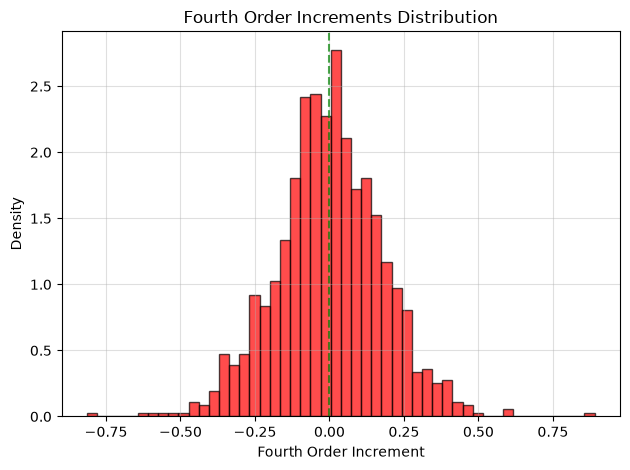

In [ ]:
plot_histogram(
    data=foi_train,
    x_label="Fourth Order Increment",
    y_label="Density",
    title="Fourth Order Increments Distribution",
    color_idx=1)

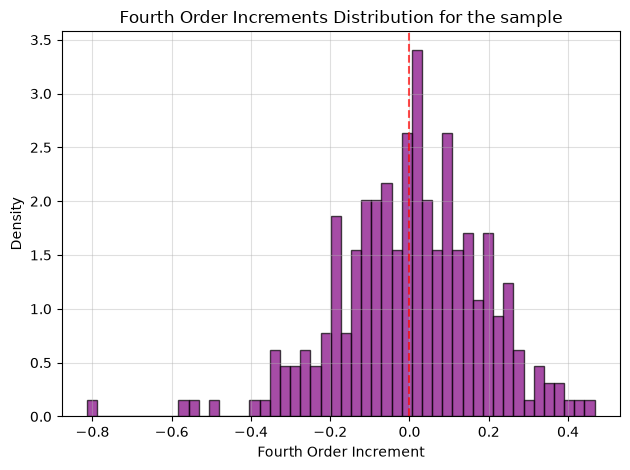

In [10]:
sample = np.random.choice(tfourth_order, 252, replace=False)


plot_histogram(
    data=sample,
    x_label="Fourth Order Increment",
    y_label="Density",
    title="Fourth Order Increments Distribution for the sample",
    color_idx=0)

b) Reconstruct prices using the last training price and the last available first-, second-, and third-order
increments as starting values. State all reconstruction recurrences

let a = d_3,t = (by definition) x_t ​− 3x_t−1 ​+ 3x_t−2 ​− x_t−3;

let b = d_3,t-1 = x_t-1 - 3x_t-2 + 3x_t-3 - x_t-4

then a - b = x_t - 4x_t-1 + 6x_t-2 - 4x_t-3 - x_t-4 = (by definition) d_4,t, => d_3,t = d_4,t + d_3,t-1  

similarly for d_2,t and d_1,t

d_3,t = d_2,t - d_2,t-1 => d_2,t = d_3,t + d_2,t-1
d_2,t = d_1,t - d_1,t-1 => d_1,t = d_2,t + d_1, t-1
d_1,t = x_t - x_t-1 => x_t = x_t-1 + d_1,t (1)

x_t = log(S_t) => x_t = exp(S_t)

Therefore, we will use the 4th order increments, starting from the last price

In [11]:
last_price = train_list[-1]
print(last_price)

449.7200012207031


In [17]:
# last increments
d1, d2, d3 = tfirst_order[-1], tsecond_order[-1], tthrid_order[-1]

In [ ]:
def simulate_price(
    first_order: float,
    second_order: float,
    third_order: float,
    seed: list[float], # a list of generated fourth order increments)
    last_price: float
) -> list[float] :

    pred_prices = []

    for i in range(len(seed)):
        d4 = seed[i]
        d3 = third_order + d4
        d2 = second_order + d3
        d1 = first_order + d2
        pred_prices.append(np.exp(np.log(last_price) + d1))
    
    return pred_prices


In [23]:
pred_prices = simulate_price(
    first_order=d1,
    second_order=d2,
    third_order=d3,
    seed=sample,
    last_price=last_price)
print(pred_prices[0:10])

[np.float64(654.8006448951463), np.float64(776.3045824858798), np.float64(612.4112014560362), np.float64(673.742155015595), np.float64(712.3112961169957), np.float64(860.3385403701124), np.float64(781.7718117010328), np.float64(825.5033873257779), np.float64(736.4888777898568), np.float64(720.872782621445)]


c) generate 100 paths and display their pointwise quantiles as a fan chart. Investigate the sensitivity to initial
conditions and the sampling rule, including whether reconstructed paths grow implausibly large or small

In [46]:
# run with replace = True / False, and with different sample sizes
prices = []
depth = 100 # number of simulations
simulated_prices = []

for _ in range(depth):

    seed = np.random.choice(sample, size=112, replace=True)

    prices = simulate_price(d1, d2, d3, seed, last_price)
    simulated_prices.append(prices)

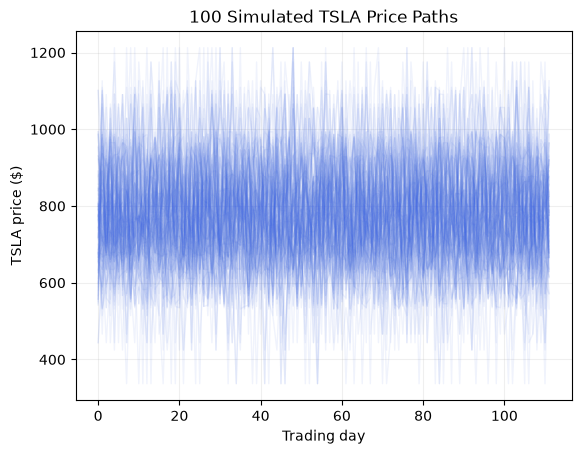

In [47]:
vals = np.array(simulated_prices)

for val in vals:

    alpha = 0.08
    plt.plot(val, color="royalblue", alpha=alpha, linewidth=1)

plt.xlabel("Trading day")
plt.ylabel("TSLA price ($)")
plt.title("100 Simulated TSLA Price Paths")
plt.grid(alpha=0.2)
plt.show()


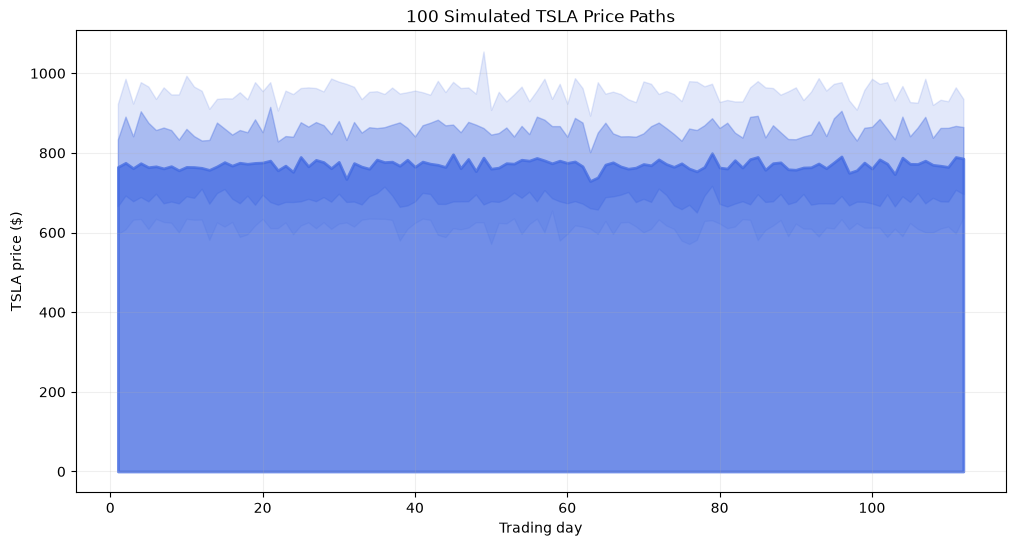

In [48]:
days = np.arange(1, vals.shape[1] + 1)
q_10, q_25, q_50, q_75, q_90 = np.quantile(
    vals, [0.10, 0.25, 0.5, 0.75, 0.90], axis=0
)

plt.figure(figsize=(12, 6))
plt.fill_between(days, q_10, q_90, alpha=0.15, color='royalblue',
        label="10-90th percentile")

plt.fill_between(days, q_25, q_75, alpha=0.35, color='royalblue',
        label="25-75th percentile")

plt.fill_between(days, q_50, alpha=0.75, color='royalblue', linewidth=2,
        label="Median")
plt.xlabel("Trading day")
plt.ylabel("TSLA price ($)")
plt.title("100 Simulated TSLA Price Paths")
plt.grid(alpha=0.2)
plt.show()

d) compare the simulated paths with the reserved observations. Explain why fitting an increment histogram
alone does not validate either its independence assumption or its use for prediction.

Text(0.5, 1.0, 'Tesla (TSLA) stock price (USD)')

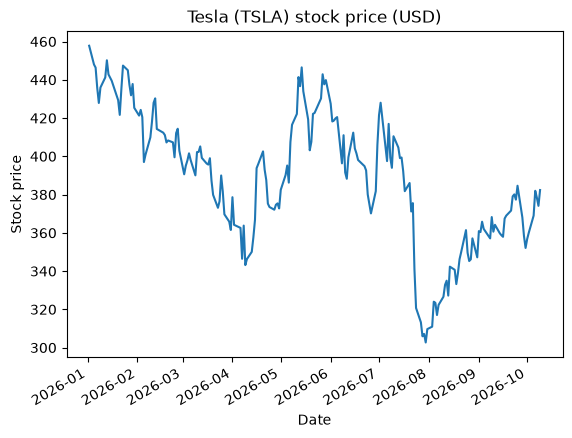

In [49]:
plt.plot(test_data['Open'])
plt.gcf().autofmt_xdate()
plt.xlabel("Date")
plt.ylabel("Stock price")
plt.title("Tesla (TSLA) stock price (USD)")

As the sample sizes increases, so do the reconstructed paths. Additionally, one observes that the 'model' doesn't really 'learn' anything meaningful. From the first chart, it's clear that the variance in the prices is so high, that it's almost a noise. Therefore, it's not really useful.


The independent assumpption is erroneous when fitting an increment histogram due to several reasons: there are aspects that influence the stock prices, such as global sentiments, news in the corporate world, mergers, or other material conditions, which are not directly observed, but nonetheless have a clear impact; as none of them are explicitly modelled by such a histogram, it cannot be properly used for inference.

Fitting a histogram is not enough for various reasons: for once, 'past returns don't guarantee future returns' and simultaneously, there were no market dynamics that were learned in the process. In this sense, this model it's too simplistic.

As a last note, even state-of-the-art timeseries prediction algorithms that use deep learning architectures do not make predictions for such long durations, most of them being somewhat 'accurate' for the immediate future (i.e. minutes / hours).